# SOTA Transfer Learning

Two lightweight, mobile/edge-friendly pretrained backbones, adapted to the 9 RealWaste classes by **freezing** the ImageNet feature extractor and training only a new classification head:

- **SOTA 1: MobileNetV2** — depthwise-separable convs + inverted residuals, designed specifically for mobile inference.
- **SOTA 2: SqueezeNet1_1** — "fire modules" (squeeze + expand 1x1/3x3 convs) built to match AlexNet-level accuracy with far fewer parameters.

Both are fine-tuned on the exact same 70/15/15 split as Model A / Model B, for 20 epochs, with Adam (`lr=0.001`) — the optimizer justified in the optimizer tuning notebook.

In [1]:
import matplotlib.pyplot as plt
import torch

from data_loader import CLASS_NAMES, get_dataloaders, set_seed
from sota_models import MobileNetV2Classifier, SqueezeNetClassifier
from train_utils import count_params, evaluate_classification, model_size_kb, train_model

EPOCHS = 20
train_loader, val_loader, test_loader = get_dataloaders(batch_size=32)

In [2]:
set_seed()
sota_models = {
    "SOTA 1 (MobileNetV2)": MobileNetV2Classifier(),
    "SOTA 2 (SqueezeNet)": SqueezeNetClassifier(),
}

for name, model in sota_models.items():
    total = sum(p.numel() for p in model.parameters())
    trainable = count_params(model)
    print(f"{name}: {total:,} total params, {trainable:,} trainable (head only, base frozen)")

SOTA 1 (MobileNetV2): 2,235,401 total params, 11,529 trainable (head only, base frozen)
SOTA 2 (SqueezeNet): 727,113 total params, 4,617 trainable (head only, base frozen)


In [3]:
histories = {}
for name, model in sota_models.items():
    print(f"\n=== {name} ===")
    trainable_params = filter(lambda p: p.requires_grad, model.parameters())
    optimizer = torch.optim.Adam(trainable_params, lr=0.001)
    history, avg_epoch_time = train_model(model, train_loader, val_loader, optimizer, epochs=EPOCHS)
    histories[name] = {"history": history, "avg_epoch_time": avg_epoch_time}


=== SOTA 1 (MobileNetV2) ===


epoch 1/20  train_loss 1.6343 train_acc 0.439  val_loss 1.3543 val_acc 0.563


epoch 2/20  train_loss 1.2471 train_acc 0.589  val_loss 1.2846 val_acc 0.558


epoch 3/20  train_loss 1.1018 train_acc 0.635  val_loss 1.1881 val_acc 0.614


epoch 4/20  train_loss 1.0299 train_acc 0.664  val_loss 1.1791 val_acc 0.596


...

epoch 16/20  train_loss 0.9796 train_acc 0.684  val_loss 1.0672 val_acc 0.652


epoch 17/20  train_loss 0.9472 train_acc 0.689  val_loss 1.0058 val_acc 0.663


epoch 18/20  train_loss 0.9571 train_acc 0.678  val_loss 1.0304 val_acc 0.662


epoch 19/20  train_loss 0.9721 train_acc 0.680  val_loss 1.0621 val_acc 0.653


epoch 20/20  train_loss 0.9373 train_acc 0.689  val_loss 1.0276 val_acc 0.674


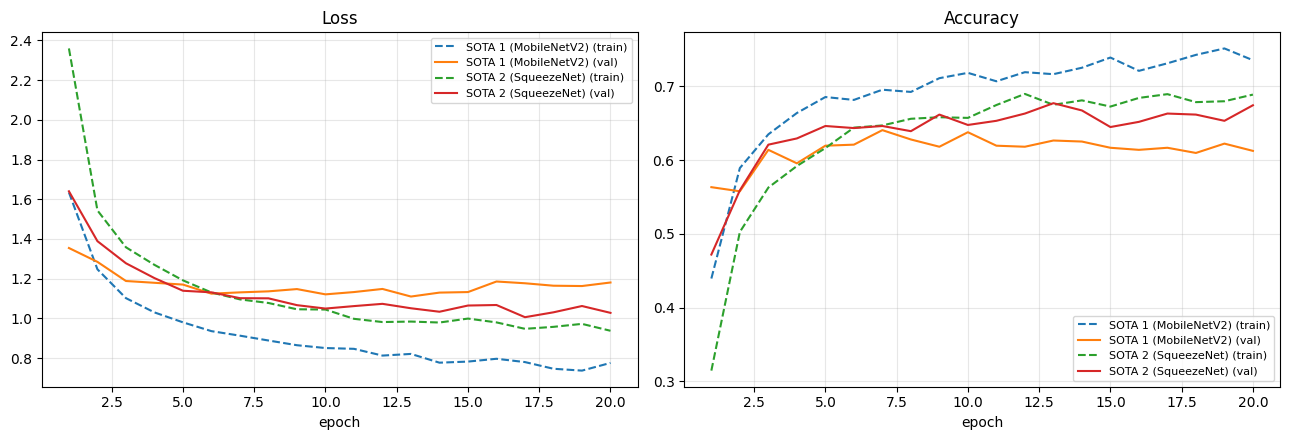

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = range(1, EPOCHS + 1)

for name, result in histories.items():
    h = result["history"]
    axes[0].plot(epochs_range, h["train_loss"], linestyle="--", label=f"{name} (train)")
    axes[0].plot(epochs_range, h["val_loss"], linestyle="-", label=f"{name} (val)")
    axes[1].plot(epochs_range, h["train_acc"], linestyle="--", label=f"{name} (train)")
    axes[1].plot(epochs_range, h["val_acc"], linestyle="-", label=f"{name} (val)")

axes[0].set_title("Loss"); axes[0].set_xlabel("epoch")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Test-set evaluation

SOTA 1 (MobileNetV2): test_acc=0.633 precision=0.634 recall=0.633 size=8.76 MB


SOTA 2 (SqueezeNet): test_acc=0.677 precision=0.679 recall=0.677 size=2.79 MB


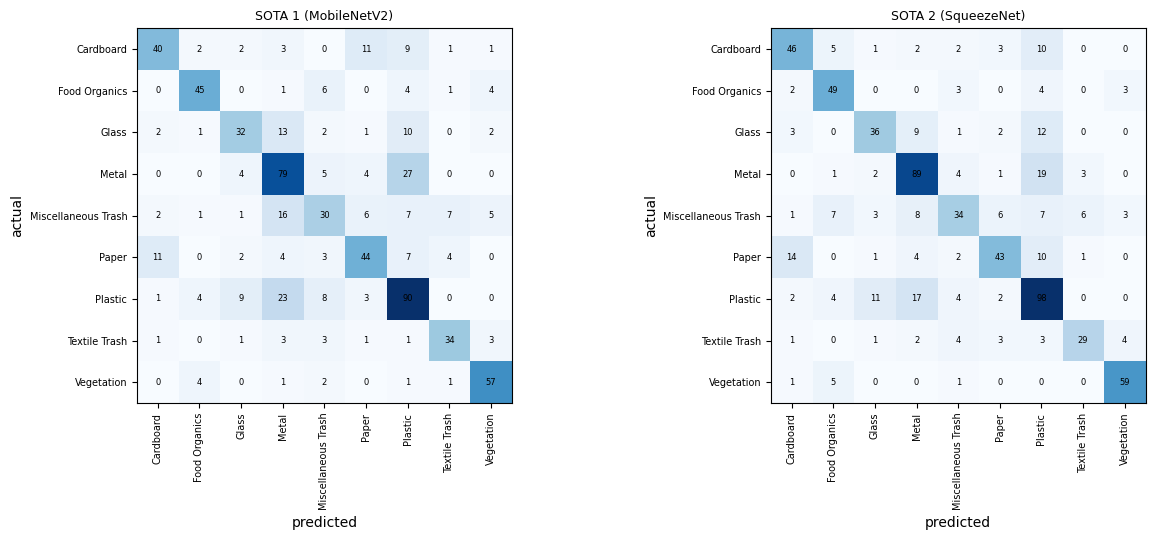

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sota_results = {}
for ax, (name, model) in zip(axes, sota_models.items()):
    metrics = evaluate_classification(model, test_loader)
    metrics["total_params"] = sum(p.numel() for p in model.parameters())
    metrics["trainable_params"] = count_params(model)
    metrics["size_kb"] = model_size_kb(model)
    metrics["avg_epoch_time"] = histories[name]["avg_epoch_time"]
    sota_results[name] = metrics

    print(f"{name}: test_acc={metrics['accuracy']:.3f} precision={metrics['precision']:.3f} "
          f"recall={metrics['recall']:.3f} size={metrics['size_kb'] / 1024:.2f} MB")

    im = ax.imshow(metrics["confusion_matrix"], cmap="Blues")
    ax.set_xticks(range(9)); ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=7)
    ax.set_yticks(range(9)); ax.set_yticklabels(CLASS_NAMES, fontsize=7)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    ax.set_title(name, fontsize=9)
    for i in range(9):
        for j in range(9):
            ax.text(j, i, metrics["confusion_matrix"][i, j], ha="center", va="center", fontsize=6)

plt.tight_layout()
plt.show()